In the following we want to implement Rogers' algorithm. Their results are based on the following :
$$
Y_0^* = \inf_{M \in H^1_0} \mathbb{E}[ \sup_{t \in [0,T]} ( Z_t - M_t )].
$$
Therefore what we try to do is to pick a suitable martingale and evaluate the expectation.

We are going to use Haugh-Kogan approach.

The martingale we are going to use is $ \pi_t  = \frac{\widetilde V_t}{B_t} +\sum_{j=1}^{t} \mathbb{E}_{j-1}\!\left[ \frac{\widetilde V_j}{B_j} - \frac{\widetilde V_{j-1}}{B_{j-1}} \right]$, therefore our quantity of interest is :
$$
\mathbb{E}_0 \left[ \max_{t\in\mathcal{T}} \left( \frac{h_t}{B_t} - \frac{\widetilde V_t}{B_t} +\sum_{j=1}^{t} \mathbb{E}_{j-1}\!\left[ \frac{\widetilde V_j}{B_j} - \frac{\widetilde V_{j-1}}{B_{j-1}} \right] \right) \right]
$$

Given that in order to compute the upper bound using Rogers-Kaugh-Hogan algorithm it is necessary to have an approximation of the value of the american option, we need to first compute the primal problem using Longstaff-Schwartz.

In [1]:
from code_utils import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def compute_upper_bound(asset, time_grid, K, r, sigma, T, l):

    tau = (T - time_grid)[:, np.newaxis]          # time to expiry
    discount_factor = np.exp(-r * time_grid)[:, np.newaxis]   # discount factor

    # European put price
	# Using Black formula is somehow cheating because you do not have for any option a closed formula for computing the value of the option!
    mask = tau > 0
    safe_tau = np.where(mask, tau, 1.0)
    d1 = (np.log(asset / K) + (r + 0.5 * sigma**2) * safe_tau) / (sigma * np.sqrt(safe_tau))
    d2 = d1 - sigma * np.sqrt(safe_tau)
    bs = K * np.exp(-r * tau) * norm.cdf(-d2) - asset * norm.cdf(-d1)  
    # fix expiry row: put value = intrinsic at T
    put_price = np.where(mask, bs, np.maximum(K - asset, 0.0))
    #Centered martingale: M_t - M_0, starts at 0
    discounted_european_put = discount_factor * put_price
    martingale = discounted_european_put - discounted_european_put[0:1, :]

    # Discounted reward Z_t
    reward = discount_factor * np.maximum(K - asset, 0.0)

    # sup_t (Z_t - M_t) per path
    return np.max(reward - l*martingale, axis=0)

def upper_bound_rogers(K, r, sigma, T, evaluation_paths, N_fine, N_coarse, seed):
	# Optimization step : grid search
	lambda_values = np.linspace(0.75, 1.2, 10)
	N_opt = 40
	dt_opt = T / N_opt
	time_opt = np.arange(0, N_opt + 1) * dt_opt
	opt_paths = 10**3
	asset_opt = S0 * simulate_gbm_nv(r, sigma, T, dt_opt, opt_paths, seed)
	best_lambda = 0
	values_opt = float('inf')
	for l in lambda_values:
		value = np.mean(compute_upper_bound(asset_opt, time_opt, K, r, sigma, T,l))
		# Trying to undertstand if this search is enough
		#print(f"Lambda: {l:.2f} | Upper bound: {value:.4f}")
		if value < values_opt:
			best_lambda = l
			values_opt = value

	dt_fine = T / N_fine
	time_fine = np.arange(0, N_fine + 1) * dt_fine

	asset_fine = S0 * simulate_gbm_nv(r, sigma, T, dt_fine, evaluation_paths, seed + 1)

	# Coarse grid: every other time point from the same paths
	asset_coarse = asset_fine[::2, :]   
	time_coarse  = time_fine[::2]

	# Price on the coarse and fine grid
	vals_fine = compute_upper_bound(asset_fine, time_fine, K, r, sigma, T, best_lambda)
	vals_coarse = compute_upper_bound(asset_coarse, time_coarse, K, r, sigma, T, best_lambda)

	# Richardson extrapolation per path, then average
	vals_richardson = 2 * vals_fine - vals_coarse
	price_richardson = np.mean(vals_richardson)
	se_rich    = np.std(vals_richardson) / np.sqrt(evaluation_paths)

	return price_richardson, se_rich, np.mean(vals_fine), np.mean(vals_coarse)

In [3]:
K = 100 # Strike price
sigma = 0.3 # Volatility 
r = 0.05  # Risk-free rate
q = 0 # Dividend yield
mu = r - q  # Drift 
T = 0.2  # Maturity 
dt = 0.004  # Time step 
N_fine = int(T / dt)  # Number of steps 
seed = 42 # Random seed for reproducibility

real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
						30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
						20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
						11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
						4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
						1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
						0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
						0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])

# Prices and uncertainty are the one realised using Richardson extrapolation
prices = np.empty(81)
uncertainty = np.empty(81)
percentage_error = np.empty(81)

N_coarse = N_fine/2
for S0 in np.arange(60,141):
	evaluation_paths = 10**5
	prices[S0-60], uncertainty[S0-60], vals_fine, vals_coarse = upper_bound_rogers(K, mu, sigma, T, evaluation_paths, N_fine, N_coarse, seed)
	# Printing the percentage error wrt the real price
	percentage_error[S0-60] = np.abs(prices[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
	print(f"S0= {S0}, Estimated Price: {prices[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error[S0-60]:.2f}%, Uncertainty: {uncertainty[S0-60]:.5f}")
	#print(f"S0= {S0}, Coarse Price: {vals_coarse:.5f}, Fine Price: {vals_fine:.5f}")


S0= 60, Estimated Price: 40.00000, Real Price: 40.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 61, Estimated Price: 39.00000, Real Price: 39.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 62, Estimated Price: 38.00000, Real Price: 38.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 63, Estimated Price: 37.00000, Real Price: 37.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 64, Estimated Price: 36.00000, Real Price: 36.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 65, Estimated Price: 35.00000, Real Price: 35.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 66, Estimated Price: 34.00000, Real Price: 34.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 67, Estimated Price: 33.00000, Real Price: 33.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 68, Estimated Price: 32.00000, Real Price: 32.00000, Percentage Error: 0.00%, Uncertainty: 0.00000
S0= 69, Estimated Price: 31.00000, Real Price: 31.00000, Percentage Error

In [9]:
np.savez('rogers_results.npz', S0=np.arange(60,141), price=prices, error=percentage_error, uncertainty=uncertainty)

In [ ]:
# Testing table 4.1 of Rogers' paper

# Parameters
K = 100
T = 0.5
sigma = 0.4
r = 0.06
S0_values = [80, 85, 90, 95, 100, 105, 110, 115, 120]

for S0 in S0_values:
	evaluation_paths = 5000
	N_fine = 50       # 2n steps
	N_coarse = 25   # n steps (subsampled from fine)
	price_rich, se_rich, vals_fine, vals_coarse = upper_bound_rogers(K, r, sigma, T, evaluation_paths, N_fine, N_coarse)
	print(f"S0={S0:3d} | Coarse: {np.mean(vals_coarse):.4f}  "
		f"Fine: {np.mean(vals_fine):.4f}  "
		f"Richardson: {price_rich:.4f} ± {se_rich:.4f}")

In [2]:
# LS  + Rogers/Haugh/Kogan

# Parameters
K = 100 # Strike price
sigma = 0.3 # Volatility 
r = 0.05  # Risk-free rate
q = 0 # Dividend yield
mu = r - q  # Drift 
T = 0.2  # Maturity 
dt = 0.004  # Time step 
N = int(T / dt) # Number of steps 
npaths_train= 10**5 # Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**6 # Number of paths for estimating the price of the option 
max_deg = 4 # Degree of the polynomial basis for regression
seed = 42 # Random seed for reproducibility

real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
                        30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
                        20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
                        11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
                        4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
                        1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
                        0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
                        0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


# Paths simulation 
train_set = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
test_set = simulate_gbm( mu, sigma, T, dt, npaths_pricing, seed = seed + 1)

# The training paths are used to determine the value fo the american option, the continuation value and therefore
# the optimal stopping rule and the estimate of the lower bound. Given that the upper bound estimated through Rogers/Haugh/Kogan
# used the value and the continuation value in order to determine the martingale for the dual approach, we are going to use the same
# paths in order to determine the upper bound!

# Applying transformation
train_log = transformation(train_set)
test_log = transformation(test_set)

# Discount factors for each time step
discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
basis_train = np.ones((N-1,npaths_train, max_deg + 1))	
basis_pricing = np.ones((N-1, npaths_pricing, max_deg + 1))
for d in range(1, max_deg + 1):
    basis_train[:, :, d] = train_log[1:N,:] * basis_train[:, :, d-1]
    basis_pricing[:, :, d] = test_log[1:N,:] * basis_pricing[:, :, d-1]

#continuation_value = {}
#option_value = {}
coefficients = {}

lower_bound = np.empty(81)
#uncertainty_ls = np.empty(81)
#percentage_error_ls = np.empty(81)

upper_bound_rhg = np.empty(81)
uncertainty_rhg = np.empty(81)
percentage_error_rhg = np.empty(81)

for S0 in np.arange(60,141):
    # This gives us the lower bound for the price of the american
    # train_deg = np.zeros(N-1, dtype=int) # Degree of the polynomial basis used for regression at each time step

    lower_bound[S0-60], _, coefficients[S0], _, _, _ = lower_bound_ls(K, S0, T, dt, train_set, test_set, discount_factors, npaths_train, npaths_pricing, max_deg, basis_train, basis_pricing)
    price = lower_bound[S0-60]
    # Discounted intrinsic value
    Z = np.maximum(0, K - S0 * test_set) * discount_factors[:, np.newaxis]
    # Q_tilde represents the approximation of the continuation value
    Q_tilde = np.zeros((N, npaths_pricing))
    V_tilde = np.zeros((N, npaths_pricing))
    V_tilde[0, :] = lower_bound[S0-60] 
    for t in range(N-1):
            Q_tilde[t, :] = basis_pricing[t, :, :] @ coefficients[S0][t]
            V_tilde[t+1, :] = np.maximum(Z[t+1, :], Q_tilde[t, :])
    Q_tilde[N-1,:] = 0  
    
    V_tilde[-1, :] = Z[-1, :]  

    # Constructing the martingale 
    martingale = np.empty((N, npaths_pricing))
    martingale[0, :] = price # Centering the martingale
    for t in range(1, N):
        martingale[t, :] = martingale[t-1,:] + V_tilde[t, :] - Q_tilde[t-1, :]
    # This does make sense because the increment is a martingale ( apart from approximation error)

    # Upper bound
    maximizing = price + np.max(Z[1:] - martingale, axis=0)

    antithetic_sum = (maximizing[:npaths_pricing//2] + maximizing[npaths_pricing//2:]) / 2
    option_price = np.mean(antithetic_sum)
    immediate_exercise = max(0, K - S0) # Immediate exercise value at time 0
    option_price = max(option_price, immediate_exercise)

    upper_bound_rhg[S0-60] = option_price
    uncertainty_rhg[S0-60] = np.std(antithetic_sum, ddof=1) / np.sqrt(npaths_pricing//2)

    # Printing the percentage error wrt the real price
    #percentage_error_ls[S0-60] = np.abs(lower_bound[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    #print(f"S0= {S0}, Lower Bound Price: {lower_bound[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_ls[S0-60]:.2f}%, Uncertainty: {uncertainty_ls[S0-60]:.5f}")
    percentage_error_rhg[S0-60] = np.abs(upper_bound_rhg[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
    print(f"S0= {S0}, Upper Bound Price: {upper_bound_rhg[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error_rhg[S0-60]:.2f}%, Uncertainty: {uncertainty_rhg[S0-60]:.5f}")


S0= 60, Upper Bound Price: 44.35134, Real Price: 40.00000, Percentage Error: 10.88%, Uncertainty: 0.00203
S0= 61, Upper Bound Price: 43.43769, Real Price: 39.00000, Percentage Error: 11.38%, Uncertainty: 0.00206
S0= 62, Upper Bound Price: 42.52474, Real Price: 38.00000, Percentage Error: 11.91%, Uncertainty: 0.00210
S0= 63, Upper Bound Price: 41.61117, Real Price: 37.00000, Percentage Error: 12.46%, Uncertainty: 0.00213
S0= 64, Upper Bound Price: 40.69951, Real Price: 36.00000, Percentage Error: 13.05%, Uncertainty: 0.00216
S0= 65, Upper Bound Price: 39.78894, Real Price: 35.00000, Percentage Error: 13.68%, Uncertainty: 0.00219
S0= 66, Upper Bound Price: 38.87869, Real Price: 34.00000, Percentage Error: 14.35%, Uncertainty: 0.00222
S0= 67, Upper Bound Price: 37.96528, Real Price: 33.00000, Percentage Error: 15.05%, Uncertainty: 0.00224
S0= 68, Upper Bound Price: 37.05874, Real Price: 32.00000, Percentage Error: 15.81%, Uncertainty: 0.00226
S0= 69, Upper Bound Price: 36.14107, Real Pric

In [3]:
np.savez('rogers_results.npz', S0=np.arange(60,141), price=upper_bound_rhg, error=percentage_error_rhg, uncertainty=uncertainty_rhg)

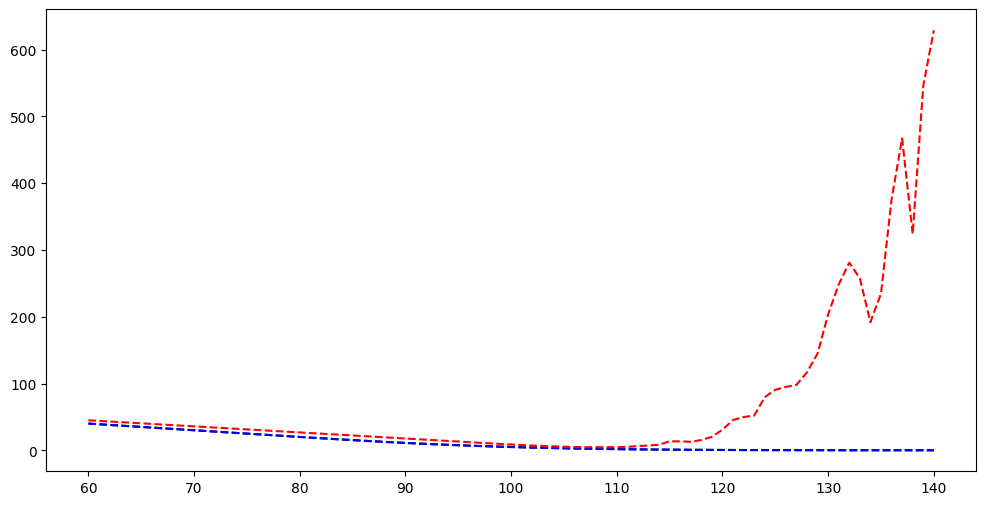

In [5]:
# Plotting the results 
plt.figure(figsize=(12, 6))
plt.plot(np.arange(60,141), real_prices, label='Real Price', color='black', linestyle='--')
plt.plot(np.arange(60,141), lower_bound, label='LS Lower Bound', color='blue', linestyle='--')
plt.plot(np.arange(60,141), upper_bound_rhg, label='RHG Upper Bound', color='red', linestyle='--')
